##=====================================================================
##PRACTICAL 1: Draw basic graphics - line, circle, arc, ellipse, rectangle
##=====================================================================


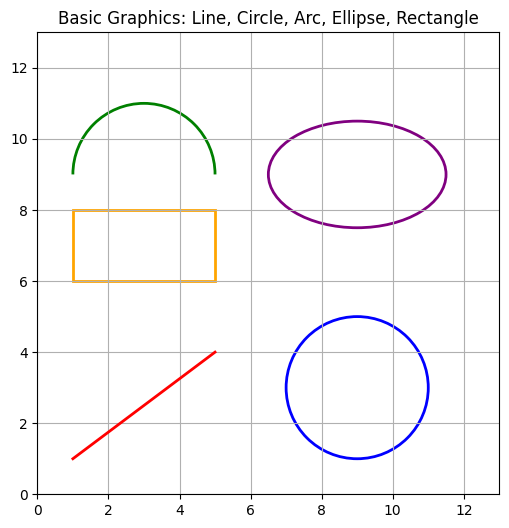

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Arc, Ellipse, Rectangle

fig, ax = plt.subplots(figsize=(8, 6))

# Line
ax.plot([1, 5], [1, 4], color='red', linewidth=2, label='Line')

# Circle: center (9, 3), radius 2
ax.add_patch(Circle((9, 3), 2, fill=False, edgecolor='blue', linewidth=2))

# Arc: center (3, 9), width 4, height 4, from 0 to 180 degrees
ax.add_patch(Arc((3, 9), 4, 4, angle=0, theta1=0, theta2=180,
                 color='green', linewidth=2))

# Ellipse: center (9, 9), width 5, height 3
ax.add_patch(Ellipse((9, 9), 5, 3, fill=False, edgecolor='purple', linewidth=2))

# Rectangle: bottom-left (1, 6), width 4, height 2
ax.add_patch(Rectangle((1, 6), 4, 2, fill=False, edgecolor='orange', linewidth=2))

ax.set_xlim(0, 13)
ax.set_ylim(0, 13)
ax.set_aspect('equal')
ax.set_title("Basic Graphics: Line, Circle, Arc, Ellipse, Rectangle")
ax.grid(True)
plt.show()



##=====================================================================
##PRACTICAL 2: Translation, Rotation and Scaling using Composite
##             Transformation
##=====================================================================



Composite Matrix:
 [[ 1.06066017 -1.06066017  5.        ]
 [ 1.06066017  1.06066017  3.        ]
 [ 0.          0.          1.        ]]


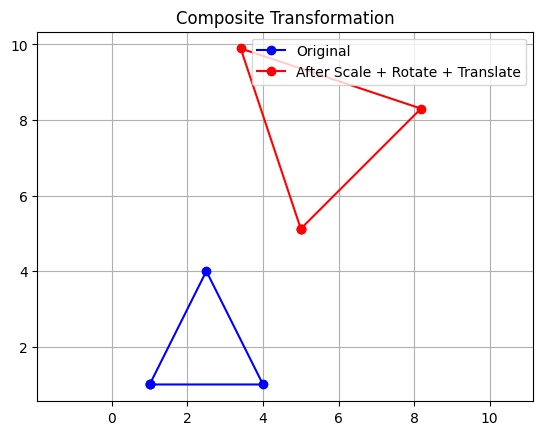

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Triangle in homogeneous coordinates (each column is a point: x, y, 1)
triangle = np.array([[1, 4, 2.5, 1],
                     [1, 1, 4,   1],
                     [1, 1, 1,   1]])

def translation(tx, ty):
    return np.array([[1, 0, tx],
                     [0, 1, ty],
                     [0, 0, 1]])

def rotation(angle_deg):
    a = np.radians(angle_deg)
    return np.array([[np.cos(a), -np.sin(a), 0],
                     [np.sin(a),  np.cos(a), 0],
                     [0,          0,         1]])

def scaling(sx, sy):
    return np.array([[sx, 0,  0],
                     [0,  sy, 0],
                     [0,  0,  1]])

# Composite transformation: first Scale, then Rotate, then Translate
# Matrices are multiplied in reverse order of application: T * R * S
S = scaling(1.5, 1.5)
R = rotation(45)
T = translation(5, 3)
composite = T @ R @ S

print("Composite Matrix:\n", composite)

result = composite @ triangle

def draw(points, color, label):
    xs = list(points[0]) + [points[0][0]]
    ys = list(points[1]) + [points[1][0]]
    plt.plot(xs, ys, color=color, marker='o', label=label)

draw(triangle, 'blue', 'Original')
draw(result, 'red', 'After Scale + Rotate + Translate')

plt.title("Composite Transformation")
plt.axis('equal')
plt.grid(True)
plt.legend()
plt.show()


##=====================================================================
##PRACTICAL 3: Draw a circle using Midpoint Implementation Method
##=====================================================================


Enter center x: 5
Enter center y: 4
Enter radius: 8


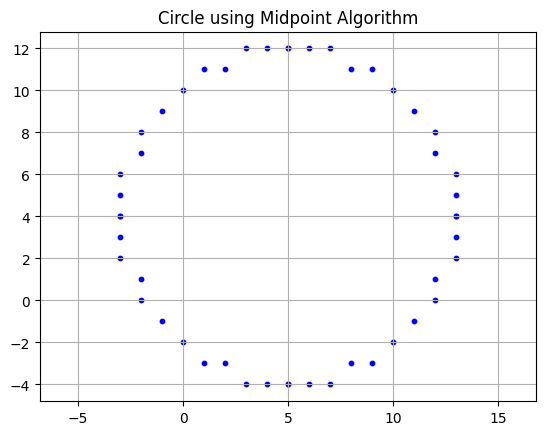

In [3]:

import matplotlib.pyplot as plt

def midpoint_circle(xc, yc, r):
    points = []
    x, y = 0, r
    p = 1 - r                       # initial decision parameter

    while x <= y:
        # 8-way symmetry
        points += [( x + xc,  y + yc), (-x + xc,  y + yc),
                   ( x + xc, -y + yc), (-x + xc, -y + yc),
                   ( y + xc,  x + yc), (-y + xc,  x + yc),
                   ( y + xc, -x + yc), (-y + xc, -x + yc)]
        x += 1
        if p < 0:
            p = p + 2 * x + 1
        else:
            y -= 1
            p = p + 2 * (x - y) + 1
    return points

xc = int(input("Enter center x: "))
yc = int(input("Enter center y: "))
r  = int(input("Enter radius: "))

pts = midpoint_circle(xc, yc, r)
xs = [p[0] for p in pts]
ys = [p[1] for p in pts]

plt.scatter(xs, ys, s=10, color='blue')
plt.title("Circle using Midpoint Algorithm")
plt.axis('equal')
plt.grid(True)
plt.show()



##=====================================================================
##PRACTICAL 4: Draw Bezier curve
##=====================================================================


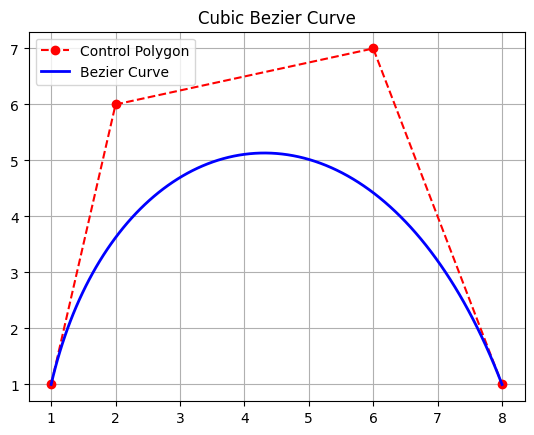

In [4]:

import numpy as np
import matplotlib.pyplot as plt
from math import comb

def bezier_curve(control_points, num=100):
    control_points = np.array(control_points)
    n = len(control_points) - 1
    t = np.linspace(0, 1, num)
    curve = np.zeros((num, 2))
    for i in range(n + 1):
        # Bernstein polynomial
        b = comb(n, i) * (t ** i) * ((1 - t) ** (n - i))
        curve += np.outer(b, control_points[i])
    return curve

# 4 control points -> Cubic Bezier curve
P = [(1, 1), (2, 6), (6, 7), (8, 1)]
curve = bezier_curve(P)

P = np.array(P)
plt.plot(P[:, 0], P[:, 1], 'ro--', label='Control Polygon')
plt.plot(curve[:, 0], curve[:, 1], 'b-', linewidth=2, label='Bezier Curve')
plt.title("Cubic Bezier Curve")
plt.legend()
plt.grid(True)
plt.show()



##=====================================================================
##PRACTICAL 5: Rotate a rectangle about its midpoint
##=====================================================================


Enter rotation angle (degrees): 45


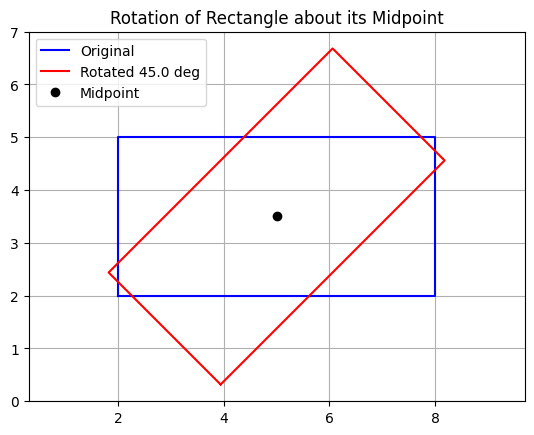

In [5]:

import numpy as np
import matplotlib.pyplot as plt

# Rectangle corners (x1,y1) bottom-left and (x2,y2) top-right
x1, y1, x2, y2 = 2, 2, 8, 5
rect = np.array([[x1, x2, x2, x1, x1],
                 [y1, y1, y2, y2, y1]], dtype=float)

# Midpoint of the rectangle
mx, my = (x1 + x2) / 2, (y1 + y2) / 2

angle = float(input("Enter rotation angle (degrees): "))
a = np.radians(angle)

# Step 1: translate midpoint to origin
# Step 2: rotate
# Step 3: translate back
shifted = rect - np.array([[mx], [my]])
R = np.array([[np.cos(a), -np.sin(a)],
              [np.sin(a),  np.cos(a)]])
rotated = R @ shifted + np.array([[mx], [my]])

plt.plot(rect[0], rect[1], 'b-', label='Original')
plt.plot(rotated[0], rotated[1], 'r-', label=f'Rotated {angle} deg')
plt.plot(mx, my, 'ko', label='Midpoint')
plt.title("Rotation of Rectangle about its Midpoint")
plt.axis('equal')
plt.grid(True)
plt.legend()
plt.show()



##=====================================================================
##PRACTICAL 6: Clip a line using Liang-Barsky Method
##=====================================================================


Clipped line: (3.00, 3.56) to (7.43, 7.00)


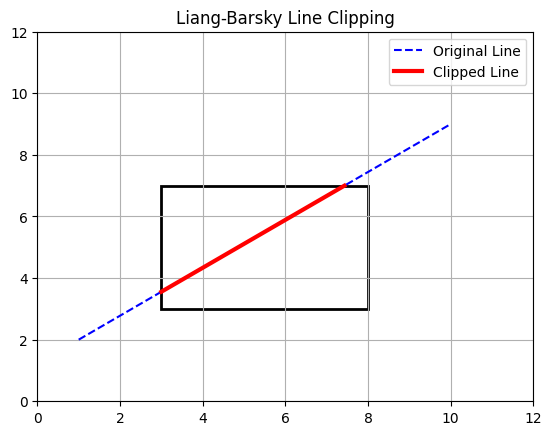

In [6]:

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

def liang_barsky(x1, y1, x2, y2, xmin, ymin, xmax, ymax):
    dx = x2 - x1
    dy = y2 - y1
    p = [-dx, dx, -dy, dy]
    q = [x1 - xmin, xmax - x1, y1 - ymin, ymax - y1]
    u1, u2 = 0.0, 1.0

    for i in range(4):
        if p[i] == 0:                 # line parallel to this boundary
            if q[i] < 0:
                return None           # outside -> rejected
        else:
            u = q[i] / p[i]
            if p[i] < 0:
                u1 = max(u1, u)
            else:
                u2 = min(u2, u)

    if u1 > u2:
        return None                   # completely outside

    return (x1 + u1 * dx, y1 + u1 * dy,
            x1 + u2 * dx, y1 + u2 * dy)

# Clipping window
xmin, ymin, xmax, ymax = 3, 3, 8, 7

# Line to be clipped
x1, y1, x2, y2 = 1, 2, 10, 9

result = liang_barsky(x1, y1, x2, y2, xmin, ymin, xmax, ymax)

fig, ax = plt.subplots()
ax.add_patch(Rectangle((xmin, ymin), xmax - xmin, ymax - ymin,
                       fill=False, edgecolor='black', linewidth=2))
ax.plot([x1, x2], [y1, y2], 'b--', label='Original Line')

if result:
    cx1, cy1, cx2, cy2 = result
    ax.plot([cx1, cx2], [cy1, cy2], 'r-', linewidth=3, label='Clipped Line')
    print("Clipped line: (%.2f, %.2f) to (%.2f, %.2f)" % (cx1, cy1, cx2, cy2))
else:
    print("Line is completely outside the window")

ax.set_title("Liang-Barsky Line Clipping")
ax.set_xlim(0, 12)
ax.set_ylim(0, 12)
ax.grid(True)
ax.legend()
plt.show()




##=====================================================================
##PRACTICAL 7: Standard Perspective Projection in 3-Dimensions
##=====================================================================


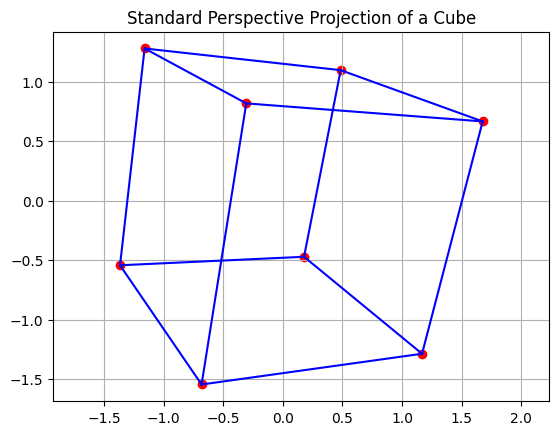

In [7]:

import numpy as np
import matplotlib.pyplot as plt

# Cube vertices (side 2, centred at origin)
v = np.array([[-1, -1, -1], [ 1, -1, -1], [ 1,  1, -1], [-1,  1, -1],
              [-1, -1,  1], [ 1, -1,  1], [ 1,  1,  1], [-1,  1,  1]],
             dtype=float)

edges = [(0,1),(1,2),(2,3),(3,0),   # back face
         (4,5),(5,6),(6,7),(7,4),   # front face
         (0,4),(1,5),(2,6),(3,7)]   # connecting edges

# Rotate cube slightly so it looks 3D
def rot_x(a):
    a = np.radians(a)
    return np.array([[1, 0, 0],
                     [0, np.cos(a), -np.sin(a)],
                     [0, np.sin(a),  np.cos(a)]])

def rot_y(a):
    a = np.radians(a)
    return np.array([[ np.cos(a), 0, np.sin(a)],
                     [0, 1, 0],
                     [-np.sin(a), 0, np.cos(a)]])

v = v @ rot_x(20).T @ rot_y(30).T

# Perspective projection:
# Centre of projection at (0, 0, d), projection plane z = 0
d = 6
factor = d / (d - v[:, 2])
x_p = v[:, 0] * factor
y_p = v[:, 1] * factor

for e in edges:
    plt.plot([x_p[e[0]], x_p[e[1]]], [y_p[e[0]], y_p[e[1]]], 'b-')
plt.scatter(x_p, y_p, color='red')

plt.title("Standard Perspective Projection of a Cube")
plt.axis('equal')
plt.grid(True)
plt.show()




##=====================================================================
##PRACTICAL 8: Parallel Projection in 3-Dimensions
##             (Orthographic + Oblique/Cavalier)
##=====================================================================


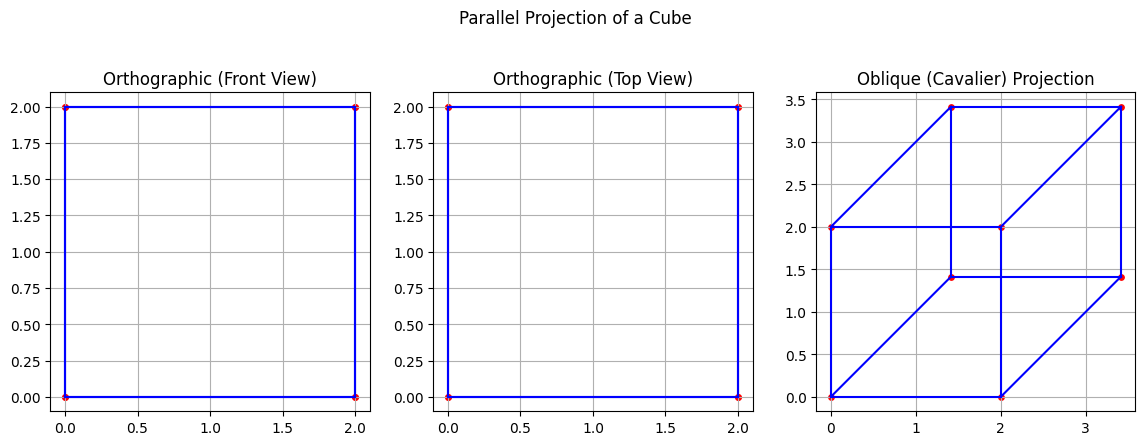

In [8]:

import numpy as np
import matplotlib.pyplot as plt

v = np.array([[0, 0, 0], [2, 0, 0], [2, 2, 0], [0, 2, 0],
              [0, 0, 2], [2, 0, 2], [2, 2, 2], [0, 2, 2]], dtype=float)

edges = [(0,1),(1,2),(2,3),(3,0),
         (4,5),(5,6),(6,7),(7,4),
         (0,4),(1,5),(2,6),(3,7)]

def draw(ax, x, y, title):
    for e in edges:
        ax.plot([x[e[0]], x[e[1]]], [y[e[0]], y[e[1]]], 'b-')
    ax.scatter(x, y, color='red', s=15)
    ax.set_title(title)
    ax.set_aspect('equal')
    ax.grid(True)

fig, axs = plt.subplots(1, 3, figsize=(14, 5))

# 1. Orthographic (Front view): drop z coordinate
draw(axs[0], v[:, 0], v[:, 1], "Orthographic (Front View)")

# 2. Orthographic (Top view): drop y coordinate
draw(axs[1], v[:, 0], v[:, 2], "Orthographic (Top View)")

# 3. Oblique (Cavalier) projection with angle 45 degrees, L = 1
alpha = np.radians(45)
L = 1
x_o = v[:, 0] + v[:, 2] * L * np.cos(alpha)
y_o = v[:, 1] + v[:, 2] * L * np.sin(alpha)
draw(axs[2], x_o, y_o, "Oblique (Cavalier) Projection")

plt.suptitle("Parallel Projection of a Cube")
plt.show()





##=====================================================================
##PRACTICAL 9: Digital Clock
##=====================================================================


In [10]:
import time
from IPython.display import display, HTML, clear_output

while True:
    current_time = time.strftime("%H:%M:%S")
    current_date = time.strftime("%A, %d %B %Y")

    clear_output(wait=True)

    display(HTML(f"""
    <div style="
        background:black;
        color:lime;
        text-align:center;
        padding:30px;
        border-radius:15px;
        font-family:monospace;
    ">
        <h1 style="font-size:55px;margin:0;">
            {current_time}
        </h1>
        <p style="color:white;font-size:20px;">
            {current_date}
        </p>
    </div>
    """))

    time.sleep(1)

KeyboardInterrupt: 

##=====================================================================
##PRACTICAL 10: Animation using increasing circles filled with
##              different colors and patterns
##=====================================================================


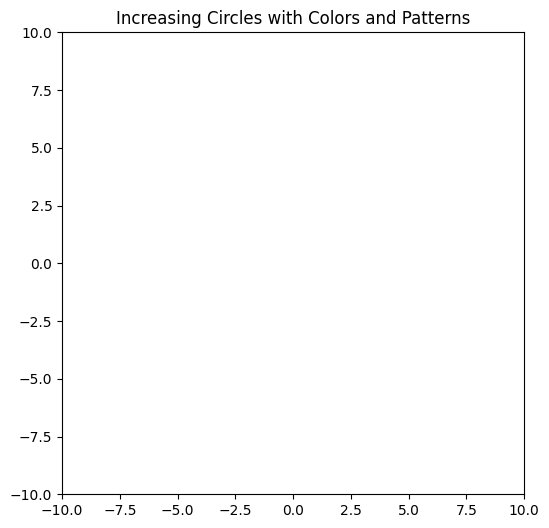

In [11]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.animation import FuncAnimation

fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)
ax.set_aspect('equal')
ax.set_title("Increasing Circles with Colors and Patterns")

colors   = ['red', 'green', 'blue', 'yellow', 'orange', 'cyan', 'magenta']
patterns = ['/', '\\', 'x', '+', 'o', '.', '*']

circles = []

def update(frame):
    # Add a new circle every 10 frames
    if frame % 10 == 0:
        i = len(circles) % len(colors)
        c = Circle((0, 0), 0.1, facecolor=colors[i], edgecolor='black',
                   hatch=patterns[i], alpha=0.6)
        ax.add_patch(c)
        circles.append(c)

    # Increase the radius of every circle
    for c in circles:
        c.set_radius(c.get_radius() + 0.05)

    # Remove circles that grew too big
    for c in circles[:]:
        if c.get_radius() > 10:
            c.remove()
            circles.remove(c)
    return circles

ani = FuncAnimation(fig, update, frames=400, interval=50, blit=False)
plt.show()



##=====================================================================
##PRACTICAL 11: Control a ball using arrow keys
##=====================================================================


In [12]:
import tkinter as tk

root = tk.Tk()
root.title("Control Ball using Arrow Keys")

WIDTH, HEIGHT = 600, 400
canvas = tk.Canvas(root, width=WIDTH, height=HEIGHT, bg="white")
canvas.pack()

r = 20            # radius
step = 10         # movement per key press
ball = canvas.create_oval(WIDTH/2 - r, HEIGHT/2 - r,
                          WIDTH/2 + r, HEIGHT/2 + r,
                          fill="red", outline="black")

def move(event):
    x1, y1, x2, y2 = canvas.coords(ball)
    dx, dy = 0, 0
    if event.keysym == "Left"  and x1 - step >= 0:
        dx = -step
    elif event.keysym == "Right" and x2 + step <= WIDTH:
        dx = step
    elif event.keysym == "Up"    and y1 - step >= 0:
        dy = -step
    elif event.keysym == "Down"  and y2 + step <= HEIGHT:
        dy = step
    canvas.move(ball, dx, dy)

root.bind("<Key>", move)
root.focus_set()
root.mainloop()



TclError: no display name and no $DISPLAY environment variable

##=====================================================================
##PRACTICAL 12: Bouncing Ball in vertical direction
##=====================================================================


In [13]:

import tkinter as tk

root = tk.Tk()
root.title("Bouncing Ball (Vertical)")

WIDTH, HEIGHT = 400, 500
canvas = tk.Canvas(root, width=WIDTH, height=HEIGHT, bg="white")
canvas.pack()

r = 25
x = WIDTH // 2
ball = canvas.create_oval(x - r, 0, x + r, 2 * r, fill="blue", outline="black")
canvas.create_line(0, HEIGHT - 2, WIDTH, HEIGHT - 2, width=3)   # ground

dy = 5            # speed (pixels per frame)

def animate():
    global dy
    canvas.move(ball, 0, dy)
    x1, y1, x2, y2 = canvas.coords(ball)

    # Reverse direction when ball hits bottom or top
    if y2 >= HEIGHT or y1 <= 0:
        dy = -dy

    root.after(20, animate)        # call again after 20 ms

animate()
root.mainloop()



TclError: no display name and no $DISPLAY environment variable